In [1]:
# Zachary Katz
# zachary_katz@mines.edu
# 11 November 2026

"""
Programatically download n tracks of SWOT L3_LR_SSH_Expert data for all available
cycles, clean, and calculate tides in an harmonic inversion.
"""

# Imports
import altimetry_downloader_aviso
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import xarray as xr
import matplotlib.pyplot as plt
from cartopy import crs as ccrs
import cartopy.feature as cfeature
import numpy as np
from utide import solve
import matplotlib.dates as mdates
from joblib import Parallel, delayed

In [2]:
import pyTMD
model_dir = "/mnt/c/Users/ZacharyKatz/Desktop/Research/Background/GOT5.6"    
model_name = "GOT5.6"
m = pyTMD.io.model(model_dir).from_database(model_name)
print(m)      
ds = m.open_dataset(group="z")

pyTMD.io.model
    name: GOT5.6


In [3]:
# Plot GOT for 8 constitutents on 1 degree grid
constits = ["M2", "S2", "N2", "K2", "K1", "O1", "P1", "Q1"]
names = [c.lower() for c in constits]
def got_constants(lon, lat, names, batch=20000):
    """Pointwise interpolation. Returns amp (m) and Greenwich phase (deg), shape (n_const, n_points)."""
    n = lon.size
    amp = np.full((len(names), n), np.nan)
    ph = np.full((len(names), n), np.nan)
    for s in range(0, n, batch):
        sl = slice(s, min(s + batch, n))
        x = xr.DataArray(lon[sl], dims="points")
        y = xr.DataArray(lat[sl], dims="points")
        local = ds.tmd.interp(x, y, extrapolate=True)
        hc = np.stack([np.asarray(local[c].values) for c in names])
        assert hc.shape == (len(names), sl.stop - sl.start), hc.shape   # catches the grid case early
        amp[:, sl] = np.abs(hc)
        ph[:, sl] = np.degrees(np.arctan2(-hc.imag, hc.real)) % 360
    return amp, ph

lon = np.arange(-180, 180, 0.5)
lat = np.arange(-90, 90, 0.5)
grid = np.meshgrid(lon, lat)
lon_raveled = grid[0].ravel()
lat_raveled = grid[1].ravel()


amp, ph = got_constants(lon_raveled, lat_raveled, names)
    

Plotting M2
Colorbar limits: (0, np.float64(1.2145499094688887))


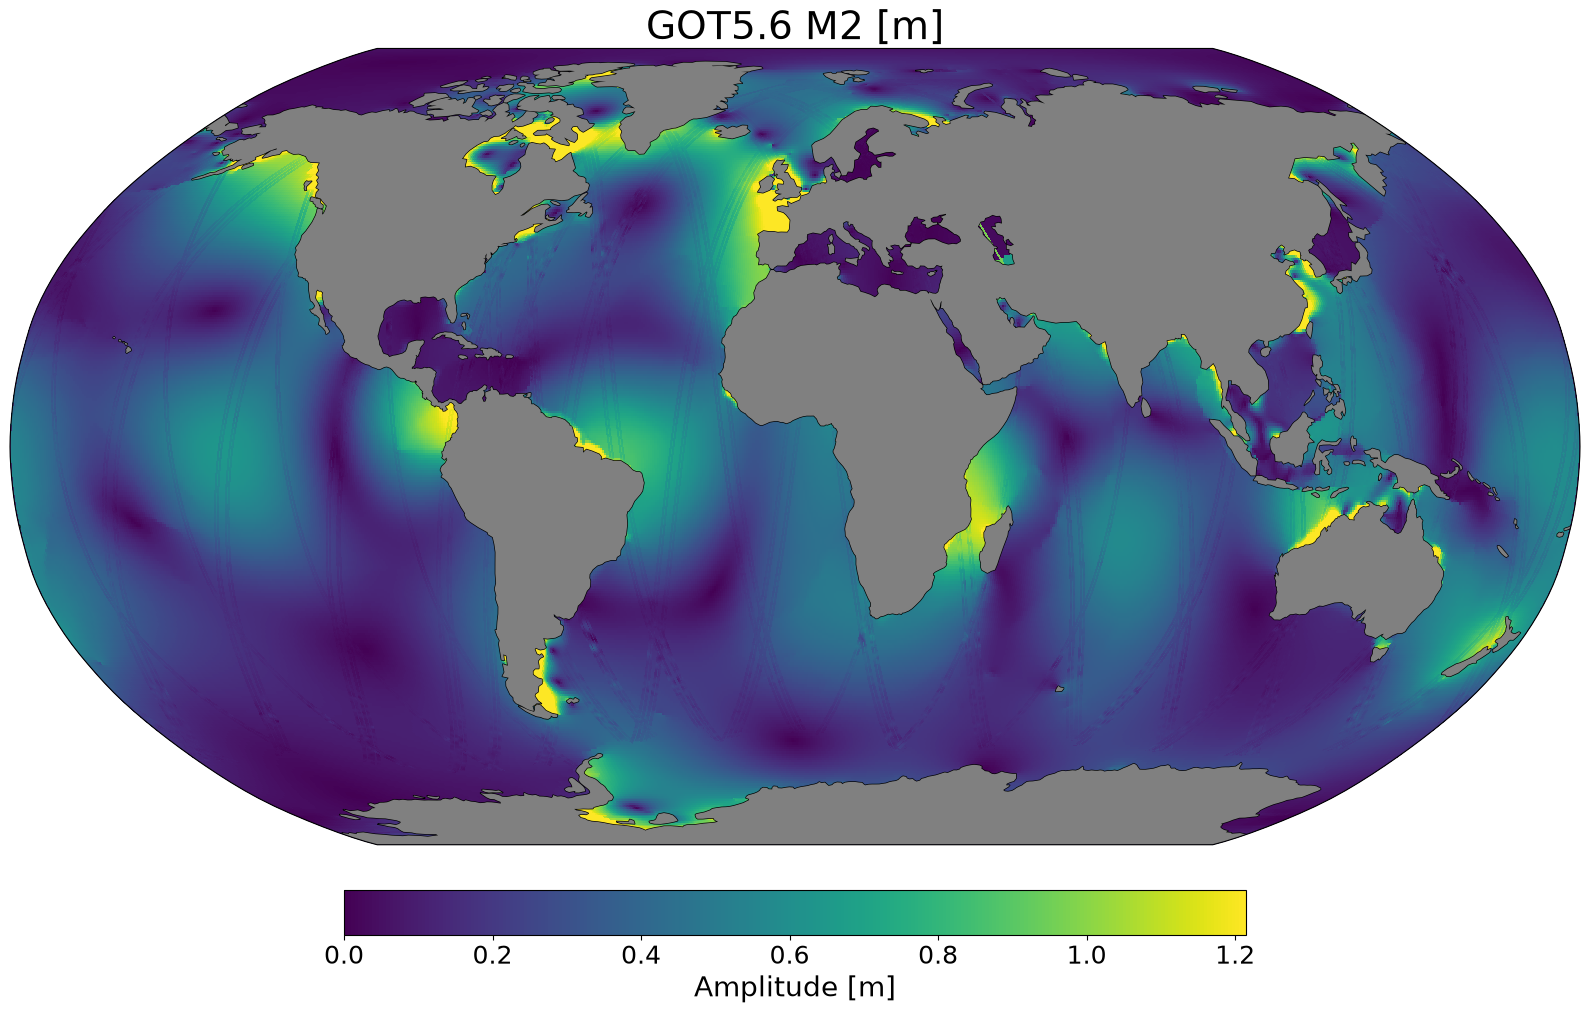

In [4]:
projection = "robinson"

constits = ["M2",]# "S2", "N2", "K2", "K1", "O1", "P1", "Q1"]
for constituent in constits[:]:
    print(f"Plotting {constituent}")
    if projection == "spilhaus":
        fig_got, ax = plt.subplots(1, 1, figsize=(16, 10), subplot_kw={"projection": ccrs.Spilhaus()})
    elif projection == "robinson":
        fig_got, ax = plt.subplots(1, 1, figsize=(16, 10), subplot_kw={"projection": ccrs.Robinson()})
    title = f"GOT5.6 {constituent} [m]"
    cmap = "viridis"

    # Get 98th percentile for colorbar limits
    k = constits.index(constituent)
    amp_got = amp[k, :]
    limit = (0, np.nanpercentile(amp_got, 94))
    print(f"Colorbar limits: {limit}")
    amp_got = amp_got.reshape((lat.size, lon.size))

    ax.pcolormesh(
        lon,
        lat,
        amp_got,
        cmap=cmap,
        vmin=limit[0],
        vmax=limit[1],
        shading="auto",
        transform=ccrs.PlateCarree(),
        rasterized=True
    )

    # Plot SWOT on top
    swot_dfs = sorted(Path("./_Data/SWOT_Tide_Results").glob("swot_tide_fit_pass_*.nc"))
    for df_path in swot_dfs:
        swot_df = xr.open_dataset(df_path)
        lon_swot = swot_df["longitude"].values
        lat_swot = swot_df["latitude"].values

        variables = [
            swot_df["amplitude"].isel(constituent=k).values,
            swot_df["amp_got"].isel(constituent=k).values,
            swot_df["vec"].isel(constituent=k).values
        ]
                
        for i, v in enumerate(variables):
            valid = (
                np.isfinite(v)
                & np.isfinite(lon_swot)
                & np.isfinite(lat_swot)
            )
            v = np.where(valid, v, np.nan)
            variables[i] = v


            sc = ax.pcolormesh(
                lon_swot,
                lat_swot,
                swot_df["amplitude"].isel(constituent=k).values,
                cmap=cmap,
                vmin=limit[0],
                vmax=limit[1],
                shading="auto",
                transform=ccrs.PlateCarree(),
                rasterized=True
            )

    ax.coastlines()
    ax.add_feature(
        cfeature.LAND,
        facecolor="gray",
        edgecolor="none",
        zorder=2
    )
    ax.set_title(title, fontsize=28)
    sm = plt.cm.ScalarMappable(
        norm=plt.Normalize(*limit),
        cmap=cmap
    )
    cbar = plt.colorbar(
        sm,
        ax=ax,
        orientation="horizontal",
        pad=0.05,
        fraction=0.05
    )
    cbar.ax.tick_params(labelsize=18)
    cbar.set_label("Amplitude [m]", fontsize=20)

    if projection == "spilhaus":
        ax.set_global()
    elif projection == "robinson":
        ax.set_global()

    fig_got.tight_layout()
    fig_got.savefig(f"./GOT_{constituent}", dpi=300, bbox_inches="tight", transparent=True)

Plotting M2


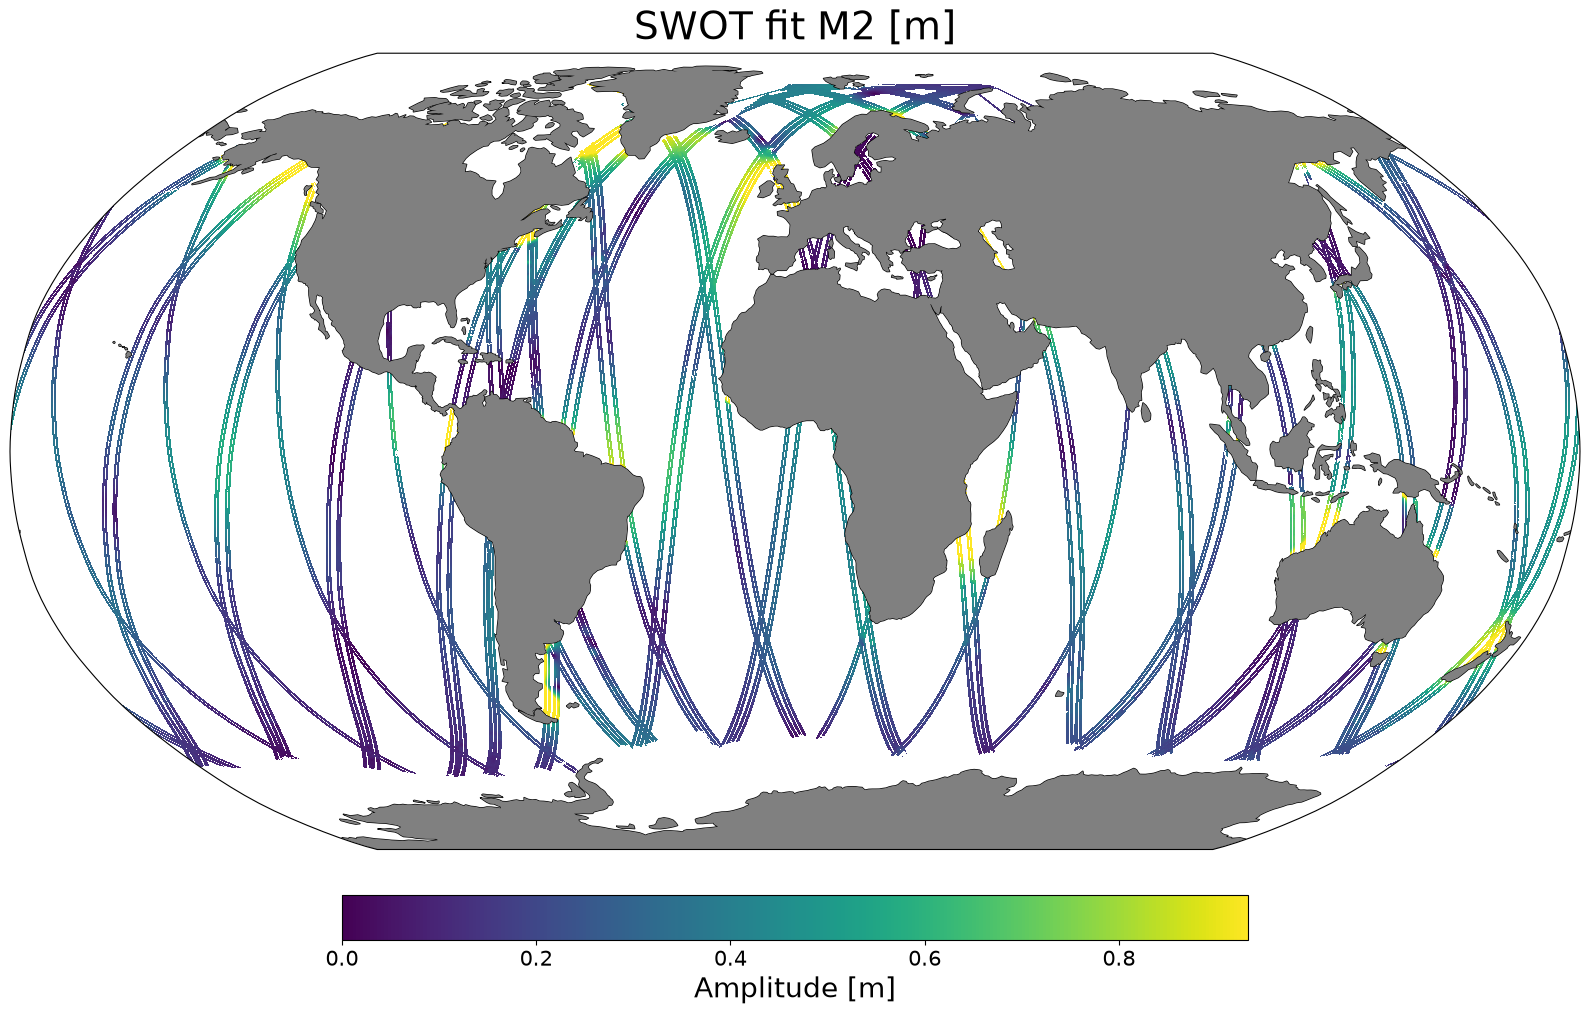

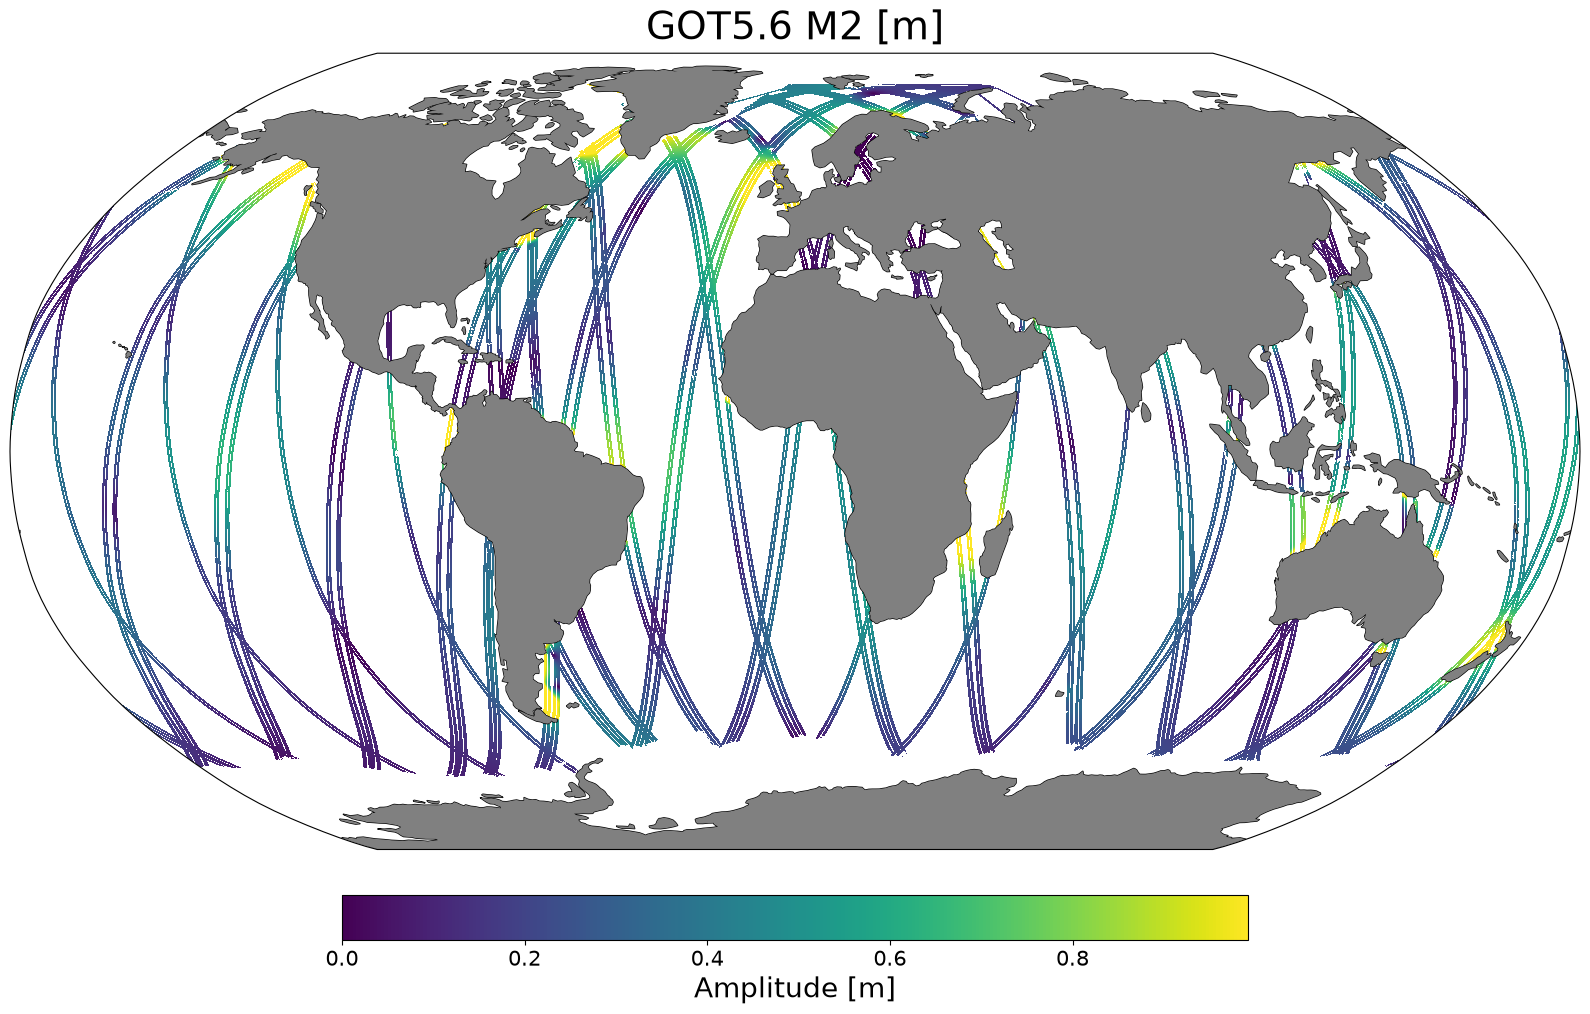

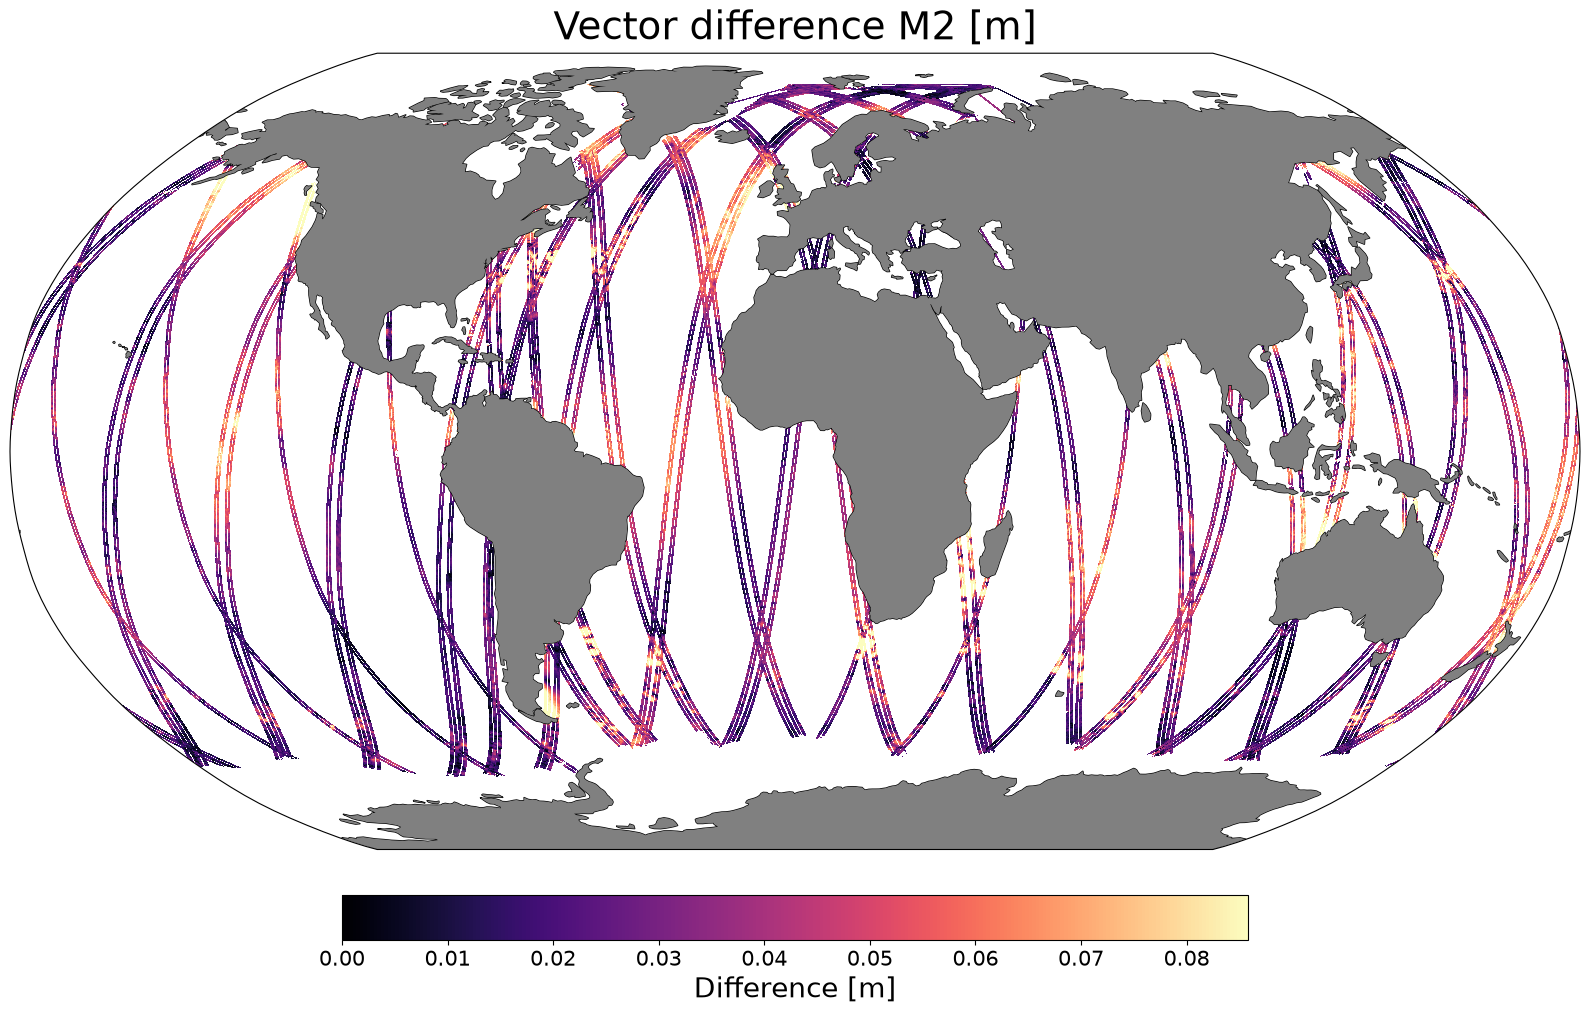

In [6]:
projections = ["robinson"]
constits = ["M2", "S2", "N2", "K2", "K1", "O1", "P1", "Q1"]
names = [c.lower() for c in constits]
for projection in projections:
    for constituent in constits[:1]:
        print(f"Plotting {constituent}")
        k = constits.index(constituent)
        files = sorted(Path(f"./_Data/SWOT_Tide_Results").glob("swot_tide_fit_pass_*.nc"))
        percentiles = [[] for _ in range(3)]
        # Calculate 98th percentile for each variable across all passes
        for path in files:
            with xr.open_dataset(path) as ds:
                for i, var in enumerate(["amplitude", "amp_got", "vec"]):
                    v = ds[var].isel(constituent=k).values
                    percentiles[i].append(v[np.isfinite(v)])
        limits = [(0, np.nanpercentile(np.concatenate(v), 98)) for v in percentiles]

        if projection == "spilhaus":
            fig_swot, ax_swot = plt.subplots(1, 1, figsize=(16, 10), subplot_kw={"projection": ccrs.Spilhaus()})
            fig_got, ax_got = plt.subplots(1, 1, figsize=(16, 10), subplot_kw={"projection": ccrs.Spilhaus()})
            fig_vec, ax_vec = plt.subplots(1, 1, figsize=(16, 10), subplot_kw={"projection": ccrs.Spilhaus()})
        elif projection == "robinson":
            fig_swot, ax_swot = plt.subplots(1, 1, figsize=(16, 10), subplot_kw={"projection": ccrs.Robinson()})
            fig_got, ax_got = plt.subplots(1, 1, figsize=(16, 10), subplot_kw={"projection": ccrs.Robinson()})
            fig_vec, ax_vec = plt.subplots(1, 1, figsize=(16, 10), subplot_kw={"projection": ccrs.Robinson()})
        titles = [f"SWOT fit {constituent} [m]",f"GOT5.6 {constituent} [m]",f"Vector difference {constituent} [m]"]
        cmaps = ["viridis", "viridis", "magma"]
        save_name = ['SWOT', 'GOT', 'Difference']

        for index, (fig, ax, ttl, cm, lim, svnm) in enumerate(zip([fig_swot, fig_got, fig_vec], [ax_swot, ax_got, ax_vec], titles, cmaps, limits, save_name)):
            for path in files:
                with xr.open_dataset(path) as ds:
                    lon = ds["longitude"].values
                    lon = (lon + 180) % 360 - 180
                    lat = ds["latitude"].values

                    if index == 0:
                        v = ds["amplitude"].isel(constituent=k).values
                    elif index == 1:
                        v = ds["amp_got"].isel(constituent=k).values
                    else:
                        v = ds["vec"].isel(constituent=k).values

                    valid = (
                        np.isfinite(v)
                        & np.isfinite(lon)
                        & np.isfinite(lat)
                    )
                    v = np.where(valid, v, np.nan)

                    # Mask cells with longitude discontinuities
                    lon_diff = np.abs(np.diff(lon, axis=1))
                    bad = np.zeros(lon.shape, dtype=bool)
                    bad[:, 1:] |= lon_diff > 180
                    bad[:, :-1] |= lon_diff > 180

                    v = np.where(bad, np.nan, v)

                    sc = ax.pcolormesh(
                        lon,
                        lat,
                        v,
                        cmap=cm,
                        vmin=lim[0],
                        vmax=lim[1],
                        shading="auto",
                        transform=ccrs.PlateCarree(),
                        rasterized=True
                    )

            ax.coastlines()
            ax.add_feature(
            cfeature.LAND,
            facecolor="gray",
            edgecolor="none",
            zorder=2
            )
            ax.set_title(ttl, fontsize=28,pad=10)
            sm = plt.cm.ScalarMappable(
                norm=plt.Normalize(*lim),
                cmap=cm
            )
            cbar = plt.colorbar(
                sm,
                ax=ax,
                orientation="horizontal",
                pad=0.05,
                fraction=0.05
            )
            cbar.ax.tick_params(labelsize=15)
            cbar.set_label(
                "Amplitude [m]" if ttl != titles[2] else "Difference [m]",
                fontsize=20,
            )

            if projection == "spilhaus":
                ax.set_global()
            elif projection == "robinson":
                ax.set_global()

            fig.tight_layout()
            fig.savefig(f"./swot_tide_fit_{constituent}_{svnm}_{projection}.png", dpi=300, bbox_inches="tight", transparent=True)
